# Bab 5: Classification

Notebook ini merangkum Bab 5 buku *Practical Statistics for Data Scientists* (Bruce, Bruce & Gedeck). Bab ini membahas klasifikasi: memprediksi apakah sebuah record termasuk kelas 1 atau 0 (misalnya pinjaman gagal bayar atau lunas), dan lebih sering lagi memperkirakan **probabilitas** (propensity) sebuah record masuk ke kelas yang diminati.

Alur umum klasifikasi dengan cutoff:

1. Tentukan probabilitas cutoff untuk kelas yang diminati.
2. Perkirakan probabilitas record termasuk kelas itu, memakai model apa pun.
3. Kalau probabilitasnya di atas cutoff, tetapkan record ke kelas tersebut.

Makin tinggi cutoff, makin sedikit record yang diprediksi sebagai 1. Makin rendah cutoff, makin banyak.

Dataset yang dipakai sama dengan buku, yaitu data pinjaman LendingClub dari repo data resmi buku. Kolom utamanya: `outcome` (`paid off` atau `default`), `purpose_`, `home_`, `emp_len_`, `payment_inc_ratio`, `dti`, `borrower_score`, `revol_bal`, `revol_util`.

Catatan: notebook ini hanya berisi penjelasan dan kode, belum dijalankan. Kode dijalankan dengan Python 3 dan library yang umum dipakai (`pandas`, `scikit-learn`, `statsmodels`, `seaborn`). Bagian SMOTE memakai `imbalanced-learn`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf

from sklearn.naive_bayes import MultinomialNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, precision_recall_fscore_support,
                             roc_curve, roc_auc_score)

sns.set_style("whitegrid")
pd.set_option("display.precision", 4)

BASE = "https://raw.githubusercontent.com/gedeck/practical-statistics-for-data-scientists/master/data/"

# Data pinjaman penuh (sekitar 45 ribu baris), kolom pertama file adalah indeks
loan_data = pd.read_csv(BASE + "loan_data.csv.gz", index_col=0)
loan_data = loan_data.drop(columns=["status"])
loan_data["outcome"] = pd.Categorical(loan_data["outcome"],
                                       categories=["paid off", "default"],
                                       ordered=True)
loan_data["purpose_"] = loan_data["purpose_"].astype("category")
loan_data["home_"] = loan_data["home_"].astype("category")
loan_data["emp_len_"] = loan_data["emp_len_"].astype("category")

# Sampel 3000 pinjaman, dipakai untuk contoh dua prediktor
loan3000 = pd.read_csv(BASE + "loan3000.csv", index_col=0)

loan_data.shape, loan3000.shape

((45342, 19), (3000, 5))

## 1. Lebih dari Dua Kategori?

Sebagian besar masalah klasifikasi punya response biner. Tapi ada juga yang punya lebih dari dua hasil, misalnya pelanggan berhenti berlangganan (Y = 2), pindah ke kontrak bulanan (Y = 1), atau menandatangani kontrak jangka panjang (Y = 0).

Hampir semua metode di bab ini bisa dipakai langsung atau dengan sedikit penyesuaian untuk response multikelas. Sering kali masalahnya lebih mudah ditangani kalau dipecah jadi serangkaian masalah biner memakai probabilitas bersyarat. Contohnya:

- Prediksi apakah Y = 0 atau Y > 0.
- Kalau Y > 0, prediksi apakah Y = 1 atau Y = 2.

Pemecahan seperti ini terutama berguna kalau satu kategori jauh lebih umum daripada yang lain.

## 2. Naive Bayes

Algoritma naive Bayes memakai probabilitas melihat nilai prediktor tertentu, **diberikan** sebuah outcome, untuk memperkirakan hal yang sebenarnya kita cari: probabilitas outcome Y = i **diberikan** nilai-nilai prediktor.

Istilah penting:

- **Conditional probability**: probabilitas suatu kejadian (X = i) kalau kejadian lain (Y = i) sudah terjadi.
- **Posterior probability**: probabilitas outcome setelah informasi prediktor diperhitungkan (berbeda dari prior probability yang belum memakai prediktor).

### Mengapa Bayes Eksak Tidak Praktis

Bayes eksak bekerja begini untuk tiap record yang akan diklasifikasi: cari semua record lain dengan profil prediktor yang sama persis, lihat kelas mana yang paling banyak di antara mereka, lalu tetapkan kelas itu ke record baru.

Masalahnya, begitu prediktor lebih dari segelintir, hampir tidak ada record yang punya kecocokan eksak. Menambah satu variabel baru dengan lima kategori yang sama sering saja sudah mengurangi peluang kecocokan lima kali lipat.

### Solusi "Naive"

Naive Bayes tidak membatasi perhitungan ke record yang cocok persis. Ia memakai seluruh data:

1. Untuk response biner Y = i, perkirakan probabilitas bersyarat tiap prediktor P(Xj | Y = i), yaitu proporsi nilai Xj di antara record dengan Y = i.
2. Kalikan probabilitas-probabilitas itu satu sama lain, lalu kalikan dengan proporsi record dengan Y = i.
3. Ulangi untuk semua kelas.
4. Perkirakan probabilitas outcome i dengan membagi nilai kelas i dengan jumlah nilai semua kelas.
5. Tetapkan record ke kelas dengan probabilitas tertinggi.

Disebut "naive" karena kita mengasumsikan tiap prediktor saling independen secara kondisional, sehingga probabilitas gabungan cukup didekati dengan hasil kali probabilitas individual.

Naive Bayes standar hanya bekerja untuk prediktor kategorikal. Untuk prediktor numerik ada dua cara: ubah jadi kategori (binning), atau pakai model probabilitas seperti distribusi normal. Kalau suatu kategori tidak pernah muncul di data latih, probabilitasnya jadi nol, karena itu implementasi biasanya memakai smoothing (Laplace smoothing).

In [2]:
# Naive Bayes butuh prediktor kategorikal, jadi diubah menjadi dummy variable dulu
predictors = ["purpose_", "home_", "emp_len_"]
outcome = "outcome"

X = pd.get_dummies(loan_data[predictors], prefix="", prefix_sep="")
y = loan_data[outcome]

naive_model = MultinomialNB(alpha=0.01, fit_prior=True)
naive_model.fit(X, y)

# Prediksi untuk pinjaman terakhir pada contoh buku (baris indeks 146)
new_loan = X.loc[146:146, :]
print("predicted class: ", naive_model.predict(new_loan)[0])

probabilities = pd.DataFrame(naive_model.predict_proba(new_loan),
                              columns=loan_data[outcome].cat.categories)
print("predicted probabilities")
print(probabilities)

predicted class:  default
predicted probabilities
   paid off  default
0    0.5624   0.4376


Naive Bayes dikenal menghasilkan estimasi probabilitas yang bias. Tapi kalau tujuannya hanya mengurutkan record berdasarkan probabilitas Y = 1, estimasi yang tidak bias tidak diperlukan, dan naive Bayes tetap memberi hasil yang baik.

**Ide kunci:**

- Naive Bayes bekerja dengan prediktor dan outcome kategorikal.
- Pertanyaannya: "di dalam tiap kategori outcome, kategori prediktor mana yang paling mungkin?"
- Informasi itu lalu dibalik untuk memperkirakan probabilitas kategori outcome, diberikan nilai prediktor.

## 3. Discriminant Analysis

Discriminant analysis adalah pengklasifikasi statistik tertua, diperkenalkan R. A. Fisher pada 1936. Varian yang paling umum adalah **linear discriminant analysis (LDA)**. Sekarang LDA lebih jarang dipakai dibanding model tree dan logistic regression, tapi masih berguna dan terkait dengan metode lain seperti principal components analysis.

Jangan tertukar dengan Latent Dirichlet Allocation yang juga disingkat LDA. Itu metode untuk teks dan NLP, tidak berhubungan.

### Covariance Matrix

**Covariance** mengukur seberapa besar dua variabel x dan z bergerak bersama:

s(x,z) = Σ (xi − x̄)(zi − z̄) / (n − 1)

Seperti korelasi, nilai positif berarti hubungan positif dan negatif berarti hubungan negatif. Bedanya, korelasi dibatasi antara −1 dan 1, sedangkan skala covariance bergantung pada skala variabelnya. **Covariance matrix** berisi varians tiap variabel di diagonal dan covariance antar pasangan variabel di luar diagonal. Matriks ini dipakai dalam perluasan multivariat dari standardisasi, yang dikenal sebagai jarak Mahalanobis.

### Fisher's Linear Discriminant

Misalkan kita ingin memprediksi outcome biner y memakai dua variabel numerik (x, z). Fisher's linear discriminant memisahkan variasi **antar** kelompok dari variasi **dalam** kelompok. LDA mencari kombinasi linear wx·x + wz·z yang memaksimalkan rasio:

SS_between / SS_within

Jumlah kuadrat antar-kelompok adalah jarak kuadrat antara dua rata-rata kelompok, sedangkan jumlah kuadrat dalam-kelompok adalah sebaran di sekitar rata-rata tiap kelompok, dibobot dengan covariance matrix. Dengan memaksimalkan yang pertama dan meminimalkan yang kedua, pemisahan antar kelompok jadi paling besar.

In [3]:
predictors = ["borrower_score", "payment_inc_ratio"]
outcome = "outcome"

loan3000["outcome"] = loan3000["outcome"].astype("category")

X = loan3000[predictors]
y = loan3000[outcome]

loan_lda = LinearDiscriminantAnalysis()
loan_lda.fit(X, y)

# Bobot linear discriminant yang diestimasi
pd.DataFrame(loan_lda.scalings_, index=X.columns)

,0
borrower_score,7.1758
payment_inc_ratio,-0.0997


Kalau prediktor dinormalisasi lebih dulu sebelum menjalankan LDA, bobot discriminant bisa dibaca sebagai ukuran pentingnya variabel. Jadi LDA menjadi cara seleksi fitur yang efisien secara komputasi.

Method `predict_proba` mengembalikan probabilitas `default` dan `paid off` untuk tiap record.

In [4]:
pred = pd.DataFrame(loan_lda.predict_proba(loan3000[predictors]),
                    columns=loan_lda.classes_)
pred.head()

,default,paid off
0,0.5535,0.4465
1,0.5590,0.4410
2,0.2727,0.7273
3,0.5063,0.4937
4,0.6100,0.3900


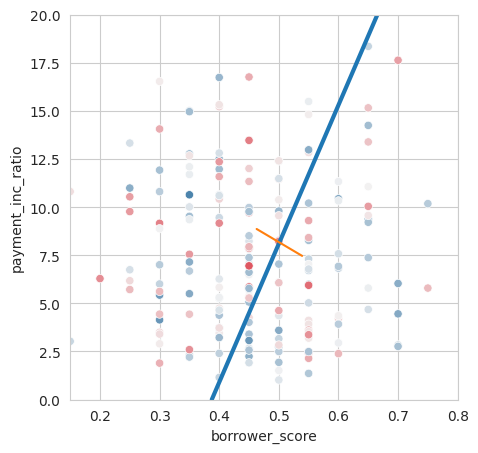

In [5]:
# Garis keputusan dari bobot (scalings) dan titik tengah rata-rata kedua kelas
center = np.mean(loan_lda.means_, axis=0)
slope = - loan_lda.scalings_[0] / loan_lda.scalings_[1]
intercept = center[1] - center[0] * slope

# Nilai borrower_score pada payment_inc_ratio = 0 dan 20
x_0 = (0 - intercept) / slope
x_20 = (20 - intercept) / slope

lda_df = pd.concat([loan3000, pred["default"]], axis=1)

fig, ax = plt.subplots(figsize=(5, 5))
g = sns.scatterplot(x="borrower_score", y="payment_inc_ratio",
                    hue="default", data=lda_df,
                    palette=sns.diverging_palette(240, 10, n=9, as_cmap=True),
                    ax=ax, legend=False)

ax.set_ylim(0, 20)
ax.set_xlim(0.15, 0.8)
ax.plot((x_0, x_20), (0, 20), linewidth=3)
ax.plot(*loan_lda.means_.transpose())
plt.show()

Titik di sebelah kiri garis diagonal diprediksi gagal bayar (probabilitas lebih dari 0.5). Prediksi yang makin jauh dari garis, ke dua arah, punya tingkat keyakinan lebih tinggi (probabilitas makin jauh dari 0.5).

### Perluasan Discriminant Analysis

- **Lebih dari dua prediktor**: LDA bekerja sama baiknya. Satu-satunya batas adalah jumlah record, karena covariance matrix butuh record yang cukup per variabel.
- **Quadratic discriminant analysis (QDA)**: pada LDA, covariance matrix diasumsikan sama untuk kedua kelompok. Pada QDA, covariance matrix boleh berbeda. Dalam praktik, perbedaannya biasanya tidak besar.

**Ide kunci:** discriminant analysis memakai prediktor kontinu atau kategorikal dan outcome kategorikal. Lewat covariance matrix ia menghitung fungsi diskriminan linear untuk membedakan satu kelas dari kelas lain. Fungsi ini diterapkan ke tiap record untuk menghasilkan skor per kelas, yang menentukan kelas prediksinya.

## 4. Logistic Regression

Logistic regression mirip regresi linear berganda, hanya saja outcome-nya biner. Seperti discriminant analysis, dan berbeda dari KNN dan naive Bayes, ia adalah pendekatan berbasis model berstruktur, bukan berbasis data. Kecepatan komputasinya tinggi dan modelnya mudah dipakai untuk menilai data baru, sehingga sangat populer.

Istilah penting:

- **Logit**: fungsi yang memetakan probabilitas keanggotaan kelas ke rentang −∞ sampai +∞ (bukan 0 sampai 1). Sinonimnya log odds.
- **Odds**: rasio "sukses" (1) terhadap "tidak sukses" (0).
- **Log odds**: response pada model yang sudah ditransformasi (sekarang linear), yang nanti dipetakan balik ke probabilitas.

### Logistic Response Function dan Logit

Kalau kita memodelkan probabilitas p secara linear, p = β0 + β1x1 + ... + βqxq, tidak ada jaminan p berada di antara 0 dan 1. Solusinya: pakai **fungsi respons logistik** (inverse logit):

p = 1 / (1 + e^−(β0 + β1x1 + ... + βqxq))

Transformasi ini menjaga p tetap di antara 0 dan 1. Dengan konsep odds, Odds(Y=1) = p / (1 − p), dan kalau kedua sisi diberi logaritma, kita dapat bentuk linear:

log(Odds(Y=1)) = β0 + β1x1 + β2x2 + ... + βqxq

Fungsi log-odds (logit) memetakan p dari [0, 1] ke seluruh bilangan riil. Setelah model linear menghasilkan log odds, kita ubah balik ke probabilitas, lalu terapkan aturan cutoff untuk menentukan kelas.

### Logistic Regression dan GLM

Kita hanya mengamati outcome biner, bukan log odds-nya, jadi dibutuhkan metode statistik khusus untuk fitting. Logistic regression adalah kasus khusus dari **generalized linear model (GLM)**.

Di scikit-learn, kelas yang dipakai adalah `LogisticRegression`. Argumen `penalty` dan `C` mengatur regularisasi L1 atau L2, yang aktif secara default. Untuk fitting tanpa regularisasi, `C` diisi nilai yang sangat besar.

In [6]:
predictors = ["payment_inc_ratio", "purpose_", "home_", "emp_len_",
              "borrower_score"]
outcome = "outcome"

X = pd.get_dummies(loan_data[predictors], prefix="", prefix_sep="",
                   drop_first=True)
y = loan_data[outcome]

logit_reg = LogisticRegression(penalty="l2", C=1e42, solver="liblinear")
logit_reg.fit(X, y)

print("intercept ", logit_reg.intercept_[0])
print("classes", logit_reg.classes_)
pd.DataFrame({"coeff": logit_reg.coef_[0]}, index=X.columns)

intercept  -1.6380882883923482
classes ['default' 'paid off']


,coeff
payment_inc_ratio,-0.0797
borrower_score,4.6110
debt_consolidation,-0.2493
home_improvement,-0.4076
major_purchase,-0.2294
medical,-0.5101
other,-0.6205
small_business,-1.2157
OWN,-0.0485
RENT,-0.1574


scikit-learn menurunkan kelas dari nilai unik di `y` dan mengurutkannya secara alfabetis. Urutan ini kebalikan dari faktor yang dipakai di R, sehingga tanda koefisiennya terbalik. `predict` mengembalikan label kelas, sedangkan `predict_proba` mengembalikan probabilitas dengan urutan seperti pada `logit_reg.classes_`.

### Generalized Linear Models

GLM punya dua komponen utama:

- **Distribusi probabilitas (family)**: binomial untuk logistic regression.
- **Link function**: fungsi transformasi yang memetakan response ke prediktor (logit untuk logistic regression).

Logistic regression adalah GLM yang paling umum. Ada juga GLM untuk data hitung (distribusi Poisson, misalnya jumlah kunjungan ke halaman web dalam jangka waktu tertentu), serta negative binomial dan gamma (sering untuk waktu, misalnya waktu sampai gagal). Penerapannya lebih rumit dan sebaiknya dihindari kecuali kita paham kegunaan dan jebakannya.

### Nilai Prediksi dari Logistic Regression

Nilai prediksi mentah ada dalam bentuk log odds. Probabilitasnya diperoleh dari fungsi respons logistik p = 1 / (1 + e^−Y).

In [7]:
# Nilai prediksi dalam bentuk log odds
pred = pd.DataFrame(logit_reg.predict_log_proba(X),
                    columns=loan_data[outcome].cat.categories)
pred.describe()

,paid off,default
count,45342.0000,45342.0000
mean,-0.7578,-0.7604
std,0.3780,0.3904
min,-2.7689,-3.5389
25%,-0.9857,-0.9772
50%,-0.6974,-0.6889
75%,-0.4722,-0.4671
max,-0.0295,-0.0648


In [8]:
# Probabilitas tersedia langsung lewat predict_proba
pred = pd.DataFrame(logit_reg.predict_proba(X),
                    columns=loan_data[outcome].cat.categories)
pred.describe()

,paid off,default
count,45342.0000,45342.0000
mean,0.5000,0.5000
std,0.1673,0.1673
min,0.0627,0.0290
25%,0.3732,0.3764
50%,0.4979,0.5021
75%,0.6236,0.6268
max,0.9710,0.9373


Nilai-nilai ini ada di skala 0 sampai 1 dan belum menyatakan apakah hasilnya `default` atau `paid off`. Kita bisa menyatakan nilai di atas 0.5 sebagai `default`. Dalam praktik, cutoff yang lebih rendah sering lebih tepat kalau tujuannya mengenali anggota kelas langka.

### Interpretasi Koefisien dan Odds Ratio

Kelebihan logistic regression: modelnya bisa menilai data baru dengan cepat tanpa hitung ulang, dan relatif mudah ditafsirkan dibanding metode klasifikasi lain. Konsep kuncinya adalah **odds ratio**. Untuk variabel faktor biner X:

odds ratio = Odds(Y=1 | X=1) / Odds(Y=1 | X=0)

Kalau odds ratio-nya 2, odds Y = 1 dua kali lebih tinggi ketika X = 1 dibanding X = 0. Kita bekerja dengan odds karena koefisien βj pada logistic regression adalah **log dari odds ratio** untuk Xj.

Contoh dari buku: koefisien `purpose_small_business` adalah 1.21526. Artinya, pinjaman untuk usaha kecil dibanding pinjaman untuk melunasi kartu kredit menaikkan odds gagal bayar terhadap lunas sebesar exp(1.21526) ≈ 3.4 kali. Pinjaman untuk membuat atau memperluas usaha kecil jelas jauh lebih berisiko.

Untuk variabel numerik, odds ratio mengukur perubahan odds untuk kenaikan satu satuan X. Kenaikan `payment_inc_ratio` dari 5 ke 6 menaikkan odds gagal bayar sebesar exp(0.08244) ≈ 1.09 kali. Sementara itu, untuk `borrower_score` (0 sampai 1), odds gagal bayar peminjam terbaik relatif terhadap yang terburuk lebih kecil dengan faktor exp(−4.61264) ≈ 0.01, jadi risiko gagal bayar peminjam dengan kelayakan kredit terburuk sekitar 100 kali lebih besar.

In [9]:
# Contoh menghitung odds ratio dari koefisien yang sudah di-fit
coef = pd.Series(logit_reg.coef_[0], index=X.columns)
odds_ratio = np.exp(coef)
odds_ratio.sort_values(ascending=False)

,0
borrower_score,100.5884
> 1 Year,1.4297
OWN,0.9527
payment_inc_ratio,0.9234
RENT,0.8544
major_purchase,0.7950
debt_consolidation,0.7793
home_improvement,0.6652
medical,0.6004
other,0.5377


### Regresi Linear dan Logistik: Persamaan dan Perbedaan

Keduanya mengasumsikan bentuk linear parametrik yang menghubungkan prediktor dengan response. Cara mengeksplorasi dan mencari model terbaik juga mirip, dan perluasan seperti spline berlaku di kedua konteks. Perbedaan mendasarnya ada dua:

- Cara model di-fit (least squares tidak berlaku).
- Sifat dan analisis residual model.

**Fitting model.** Regresi linear di-fit dengan least squares dan dievaluasi dengan RMSE serta R-squared. Pada logistic regression tidak ada solusi bentuk tertutup, sehingga model di-fit dengan **maximum likelihood estimation (MLE)**, yaitu mencari model yang paling mungkin menghasilkan data yang kita amati. Kualitas fit diukur dengan **deviance** = −2 log Pθ(X1, ..., Xn). Deviance yang lebih rendah berarti fit lebih baik. Sebagian besar praktisi tidak perlu mengurus detail algoritma fitting-nya, cukup memahami bahwa ini cara menemukan model yang baik di bawah asumsi tertentu.

**Faktor (kategorikal).** Di scikit-learn paling mudah memakai one hot encoding, dan hanya n − 1 dummy yang bisa dipakai di regresi.

### Menilai Model

Seperti metode klasifikasi lain, logistic regression dinilai dari seberapa akurat ia mengklasifikasi data baru. Seperti regresi linear, ada alat statistik standar tambahan. `statsmodels` menyediakan GLM dengan ringkasan yang lengkap.

In [10]:
y_numbers = [1 if yi == "default" else 0 for yi in y]
logit_reg_sm = sm.GLM(y_numbers, X.assign(const=1),
                      family=sm.families.Binomial())
logit_result = logit_reg_sm.fit()
logit_result.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                 Generalized Linear Model Regression Results                  
==============================================================================
Dep. Variable:                      y   No. Observations:                45342
Model:                            GLM   Df Residuals:                    45330
Model Family:                Binomial   Df Model:                           11
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -28757.
Date:                Mon, 12 Oct 2026   Deviance:                       57515.
Time:                        00:06:08   Pearson chi2:                 4.54e+04
No. Iterations:                     4   Pseudo R-squ. (CS):             0.1112
Covariance Type:            nonrobust                                         
======================================================================================
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
payment_inc_ratio      0.0797      0.002     32.058      0.000       0.075       0.085
borrower_score        -4.6126      0.084    -55.203      0.000      -4.776      -4.449
debt_consolidation     0.2494      0.028      9.030      0.000       0.195       0.303
home_improvement       0.4077      0.047      8.747      0.000       0.316       0.499
major_purchase         0.2296      0.054      4.277      0.000       0.124       0.335
medical                0.5105      0.087      5.882      0.000       0.340       0.681
other                  0.6207      0.039     15.738      0.000       0.543       0.698
small_business         1.2153      0.063     19.192      0.000       1.091       1.339
OWN                    0.0483      0.038      1.271      0.204      -0.026       0.123
RENT                   0.1573      0.021      7.420      0.000       0.116       0.199
 > 1 Year             -0.3567      0.053     -6.779      0.000      -0.460      -0.254
const                  1.6381      0.074     22.224      0.000       1.494       1.783
======================================================================================
"""

Interpretasi p-value di sini punya catatan yang sama seperti pada regresi: lebih tepat dilihat sebagai indikator relatif pentingnya variabel, bukan ukuran formal signifikansi statistik. Model logistic regression tidak punya RMSE atau R-squared, jadi dievaluasi dengan metrik klasifikasi yang lebih umum (dibahas di bagian berikutnya).

Banyak konsep dari regresi linear tetap berlaku di sini, misalnya stepwise regression, interaction terms, spline, dan masalah confounding serta variabel yang berkorelasi. Formula interface `statsmodels` mendukung perluasan ini, termasuk spline basis (`bs`):

In [11]:
# Response untuk formula harus numerik 0/1, jadi dibuat kolom baru
loan_data["default"] = (loan_data["outcome"] == "default").astype(int)

formula = ("default ~ bs(payment_inc_ratio, df=4) + purpose_ + "
           "home_ + emp_len_ + bs(borrower_score, df=4)")
model = smf.glm(formula=formula, data=loan_data, family=sm.families.Binomial())
results = model.fit()
results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                 Generalized Linear Model Regression Results                  
==============================================================================
Dep. Variable:                default   No. Observations:                45342
Model:                            GLM   Df Residuals:                    45324
Model Family:                Binomial   Df Model:                           17
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -28744.
Date:                Mon, 12 Oct 2026   Deviance:                       57487.
Time:                        00:06:09   Pearson chi2:                 4.54e+04
No. Iterations:                     5   Pseudo R-squ. (CS):             0.1117
Covariance Type:            nonrobust                                         
==================================================================================================
                                     coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------
Intercept                          1.8382      0.380      4.836      0.000       1.093       2.583
purpose_[T.debt_consolidation]     0.2491      0.028      9.020      0.000       0.195       0.303
purpose_[T.home_improvement]       0.4138      0.047      8.848      0.000       0.322       0.505
purpose_[T.major_purchase]         0.2401      0.054      4.450      0.000       0.134       0.346
purpose_[T.medical]                0.5183      0.087      5.953      0.000       0.348       0.689
purpose_[T.other]                  0.6295      0.040     15.812      0.000       0.552       0.708
purpose_[T.small_business]         1.2252      0.063     19.303      0.000       1.101       1.350
home_[T.OWN]                       0.0484      0.038      1.273      0.203      -0.026       0.123
home_[T.RENT]                      0.1581      0.021      7.456      0.000       0.117       0.200
emp_len_[T. > 1 Year]             -0.3541      0.053     -6.729      0.000      -0.457      -0.251
bs(payment_inc_ratio, df=4)[0]     0.0049      0.121      0.041      0.967      -0.232       0.241
bs(payment_inc_ratio, df=4)[1]     1.6033      0.142     11.289      0.000       1.325       1.882
bs(payment_inc_ratio, df=4)[2]     1.9033      0.488      3.900      0.000       0.947       2.860
bs(payment_inc_ratio, df=4)[3]    -0.8521      1.929     -0.442      0.659      -4.633       2.929
bs(borrower_score, df=4)[0]       -1.0045      0.476     -2.112      0.035      -1.937      -0.072
bs(borrower_score, df=4)[1]       -2.6411      0.287     -9.209      0.000      -3.203      -2.079
bs(borrower_score, df=4)[2]       -3.6984      0.473     -7.824      0.000      -4.625      -2.772
bs(borrower_score, df=4)[3]       -5.8564      0.525    -11.160      0.000      -6.885      -4.828
==================================================================================================
"""

Response di formula dibuat numerik 0/1 (kolom `default`) karena `smf.glm` tidak bisa memakai kolom kategori berurutan secara langsung.

### Analisis Residual

Perbedaan lain dengan regresi linear ada di residual. Plot residual parsial pada logistic regression biasanya menunjukkan dua awan titik: awan atas untuk response 1 (gagal bayar) dan awan bawah untuk response 0 (lunas). Ini wajar. Prediksi diukur dalam logit yang selalu bernilai terbatas, sedangkan nilai aktual 0 atau 1 sesuai logit tak hingga, sehingga residual (yang ditambahkan ke nilai fit) tidak pernah sama dengan nol. Residual parsial pada logistic regression kurang berguna dibanding pada regresi linear, tapi tetap berguna untuk mengonfirmasi perilaku non-linear dan mengenali record yang sangat berpengaruh.

Buku mencatat bahwa belum ada implementasi residual parsial di paket Python utama, dan kode untuk membuat plotnya disediakan di repositori kode sumber pendamping.

Sebagian keluaran `summary`, seperti dispersion parameter, bisa diabaikan. Parameter itu tidak berlaku untuk logistic regression dan ada karena GLM jenis lain memakainya. Residual deviance dan jumlah iterasi scoring terkait dengan metode fitting maximum likelihood.

**Ide kunci:**

- Logistic regression seperti regresi linear, tapi outcome-nya biner.
- Beberapa transformasi dibutuhkan agar model bisa di-fit sebagai model linear, dengan log dari odds ratio sebagai response.
- Setelah model linear di-fit (lewat proses iteratif), log odds dipetakan balik ke probabilitas.
- Logistic regression populer karena cepat dan menghasilkan model yang bisa dipakai menilai data baru dengan sedikit operasi aritmetika.

## 5. Mengevaluasi Model Klasifikasi

Dalam pemodelan prediktif, umumnya beberapa model dilatih, diterapkan ke holdout sample, lalu dinilai performanya. Kalau data cukup, sampel holdout ketiga yang belum dipakai sebelumnya bisa dipakai untuk memperkirakan performa model terpilih pada data yang benar-benar baru.

Istilah penting:

- **Accuracy**: persentase kasus yang diklasifikasi dengan benar.
- **Confusion matrix**: tabel (2×2 untuk kasus biner) jumlah record berdasarkan klasifikasi prediksi dan aktual.
- **Sensitivity (recall)**: persentase semua kelas 1 yang diklasifikasi benar sebagai 1.
- **Specificity**: persentase semua kelas 0 yang diklasifikasi benar sebagai 0.
- **Precision**: persentase prediksi 1 yang memang 1.
- **ROC curve**: plot sensitivity terhadap specificity.
- **Lift**: ukuran seberapa efektif model mengidentifikasi 1 yang relatif langka pada berbagai cutoff probabilitas.

Cara paling sederhana mengukur performa adalah accuracy, yaitu proporsi prediksi yang benar: (TP + TN) / ukuran sampel. Cutoff default biasanya 0.5, dan alternatifnya adalah proporsi kelas 1 di data.

### Confusion Matrix

Confusion matrix adalah inti dari metrik klasifikasi. Baris menunjukkan nilai sebenarnya dan kolom menunjukkan nilai prediksi. Elemen diagonal adalah prediksi benar, elemen di luar diagonal adalah prediksi salah.

In [12]:
pred_y = logit_reg.predict(X) == "default"
true_y = y == "default"
true_pos = true_y & pred_y
true_neg = ~true_y & ~pred_y
false_pos = ~true_y & pred_y
false_neg = true_y & ~pred_y

conf_mat = pd.DataFrame(
    [[np.sum(true_pos), np.sum(false_neg)],
     [np.sum(false_pos), np.sum(true_neg)]],
    index=["Y = default", "Y = paid off"],
    columns=["Yhat = default", "Yhat = paid off"])
conf_mat

,Yhat = default,Yhat = paid off
Y = default,14336,8335
Y = paid off,8148,14523


Kalau 1 itu langka, rasio false positive terhadap semua prediksi positif bisa tinggi. Akibatnya, prediksi 1 kemungkinan besar justru 0. Masalah ini umum pada tes skrining medis (misalnya mamografi) yang diterapkan luas: karena kondisinya langka, hasil positif belum tentu berarti benar-benar sakit. Ini sumber banyak kebingungan di masyarakat.

### Masalah Kelas Langka

Pada banyak kasus kelas yang diprediksi tidak seimbang, misalnya klaim asuransi sah versus penipuan, atau pengunjung yang hanya melihat-lihat versus yang membeli. Kelas langka (misalnya penipuan) biasanya yang lebih penting dan diberi label 1.

Kalau kelasnya tidak mudah dipisahkan, model yang paling akurat bisa saja model yang menebak semuanya 0. Misalnya hanya 0.1% pengunjung toko web yang membeli, maka model yang menebak "tidak membeli" selalu akan akurat 99.9% tetapi tidak berguna. Kita lebih senang dengan model yang kurang akurat secara keseluruhan tapi pandai menemukan pembeli, walaupun salah menandai beberapa non-pembeli.

### Precision, Recall, dan Specificity

- precision = TP / (TP + FP)
- recall (sensitivity) = TP / (TP + FN)
- specificity = TN / (TN + FP)

In [13]:
conf_mat = confusion_matrix(y, logit_reg.predict(X))
print("Precision", conf_mat[0, 0] / sum(conf_mat[:, 0]))
print("Recall", conf_mat[0, 0] / sum(conf_mat[0, :]))
print("Specificity", conf_mat[1, 1] / sum(conf_mat[1, :]))

# Semua metrik sekaligus
precision_recall_fscore_support(y, logit_reg.predict(X),
                                labels=["default", "paid off"])

Precision 0.6376089663760897
Recall 0.6323496978518812
Specificity 0.6405981209474659


(array([0.63760897, 0.63535742]),
 array([0.6323497 , 0.64059812]),
 array([0.63496844, 0.63796701]),
 array([22671, 22671]))

### ROC Curve

Ada trade-off antara recall dan specificity: menangkap lebih banyak 1 biasanya berarti salah mengklasifikasi lebih banyak 0 sebagai 1. Kurva **ROC (Receiver Operating Characteristic)** menggambarkan trade-off ini saat cutoff diubah. Sumbu y adalah recall (sensitivity), sumbu x adalah specificity (1 di kiri, 0 di kanan) atau 1 − specificity (0 di kiri, 1 di kanan). Bentuk kurvanya identik pada kedua penyajian.

Cara menghitungnya: urutkan record berdasarkan probabilitas menjadi 1 dari yang paling mungkin ke paling kecil, lalu hitung specificity dan recall kumulatif berdasarkan record yang sudah diurutkan.

ROC pertama kali dipakai pada Perang Dunia II untuk menggambarkan performa stasiun penerima radar.

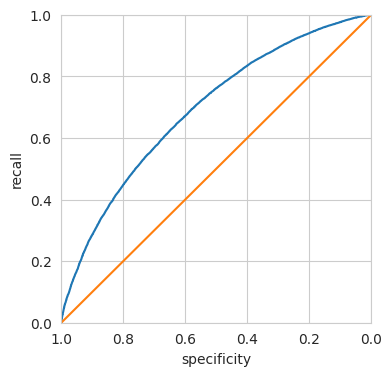

In [14]:
fpr, tpr, thresholds = roc_curve(y, logit_reg.predict_proba(X)[:, 0],
                                 pos_label="default")
roc_df = pd.DataFrame({"recall": tpr, "specificity": 1 - fpr})

ax = roc_df.plot(x="specificity", y="recall", figsize=(4, 4), legend=False)
ax.set_ylim(0, 1)
ax.set_xlim(1, 0)
ax.plot((1, 0), (0, 1))
ax.set_xlabel("specificity")
ax.set_ylabel("recall")
plt.show()

Garis putus-putus diagonal mewakili pengklasifikasi yang tidak lebih baik dari tebakan acak. Pengklasifikasi yang sangat efektif akan menempel di sudut kiri atas: banyak 1 teridentifikasi tanpa banyak 0 yang salah ditandai.

Kurva precision-recall (PR) dihitung dengan cara serupa, hanya datanya diurutkan dari yang paling tidak mungkin ke paling mungkin, lalu precision dan recall kumulatif dihitung. Kurva PR terutama berguna untuk data dengan outcome yang sangat tidak seimbang.

### AUC

Kurva ROC sendiri belum berupa satu ukuran performa. Dari kurva itu dihitung **AUC (area under the curve)**, luas total di bawah kurva ROC. Makin besar AUC, makin efektif pengklasifikasinya. AUC = 1 untuk pengklasifikasi sempurna, dan AUC = 0.5 untuk pengklasifikasi yang tak efektif (garis diagonal).

In [15]:
print(np.sum(roc_df.recall[:-1] * np.diff(1 - roc_df.specificity)))
print(roc_auc_score([1 if yi == "default" else 0 for yi in y],
                    logit_reg.predict_proba(X)[:, 0]))

0.691710795288669
0.6917108731135808


Model ini punya AUC sekitar 0.69, yang tergolong pengklasifikasi yang relatif lemah.

Waspada soal istilah false positive rate: sering tertukar dengan specificity atau sensitivity. Kadang false positive rate didefinisikan sebagai proporsi negatif sebenarnya yang tes positif, dan pada konteks lain (misalnya deteksi intrusi jaringan) sebagai proporsi sinyal positif yang sebenarnya negatif.

### Lift

AUC lebih baik dari accuracy, tapi belum sepenuhnya menjawab masalah kelas langka, yaitu kebutuhan menurunkan cutoff di bawah 0.5 supaya tidak semua record jadi 0. **Lift** memungkinkan kita menunda menjawab pertanyaan "cutoff optimalnya berapa". Kita mengurutkan record berdasarkan probabilitas jadi 1, lalu melihat, misalnya, pada 10% teratas yang diklasifikasi sebagai 1, seberapa lebih baik algoritma dibanding menebak sembarangan.

Contoh: kalau di desil teratas kita mendapat respons 0.3% dibanding 0.1% secara keseluruhan, algoritma punya lift 3 di desil itu. Lift chart (gains chart) mengukur ini di seluruh rentang data, bisa per desil atau kontinu. Cara membuatnya: buat cumulative gains chart (recall di sumbu y, jumlah record di sumbu x), lalu kurva lift adalah rasio gains kumulatif terhadap garis diagonal pemilihan acak.

Lift chart populer di kalangan profesional direct mail sebelum era e-commerce, karena direct mail mahal kalau dilakukan sembarangan. Contoh lain: otoritas pajak dengan sumber daya audit terbatas bisa memakai lift chart untuk menentukan di mana menarik garis antara laporan pajak yang diaudit dan yang dibiarkan.

Istilah **uplift** kadang berarti sama dengan lift. Arti lain yang lebih sempit: dalam A/B test, perlakuan (A atau B) dipakai sebagai prediktor, dan uplift adalah peningkatan respons yang diprediksi untuk satu kasus dengan perlakuan A dibanding B.

**Ide kunci:**

- Accuracy hanyalah langkah pertama dalam mengevaluasi model.
- Metrik lain (recall, specificity, precision) berfokus pada karakteristik performa yang lebih spesifik, misalnya recall mengukur seberapa baik model mengidentifikasi 1 dengan benar.
- AUC adalah metrik umum kemampuan model membedakan 1 dari 0.
- Lift mengukur seberapa efektif model mengidentifikasi 1, sering dihitung per desil mulai dari yang paling mungkin.

## 6. Strategi untuk Data Tidak Seimbang

Data tidak seimbang adalah data dengan outcome yang diminati (pembelian di website, penipuan asuransi, dan sebagainya) berjumlah langka. Istilah penting:

- **Undersample (downsample)**: pakai lebih sedikit record kelas yang dominan.
- **Oversample (upsample)**: pakai lebih banyak record kelas langka, dengan bootstrapping kalau perlu.
- **Up weight / down weight**: beri bobot lebih besar (atau lebih kecil) pada kelas langka (atau dominan).
- **Data generation**: seperti bootstrapping, tapi tiap record baru sedikit berbeda dari sumbernya.

### Undersampling

Kalau data cukup, salah satu solusinya adalah undersampling kelas dominan, supaya data yang dimodelkan lebih seimbang. Dasar idenya: data kelas dominan punya banyak record yang redundan. Data yang lebih kecil dan seimbang membuat performa model lebih baik dan lebih mudah dipersiapkan serta dieksplorasi. Seberapa banyak data cukup tergantung aplikasinya, tapi umumnya puluhan ribu record kelas yang kurang dominan sudah memadai.

Data pinjaman yang dipakai pada logistic regression tadi berasal dari training set yang seimbang (separuh lunas, separuh gagal bayar). Di data penuh, hanya sekitar 19% pinjaman yang gagal bayar. Apa yang terjadi kalau data penuh dipakai untuk melatih model?

In [16]:
full_train_set = pd.read_csv(BASE + "full_train_set.csv.gz")
full_train_set["outcome"] = pd.Categorical(full_train_set["outcome"],
                                            categories=["paid off", "default"],
                                            ordered=True)

print("percentage of loans in default: ",
      100 * np.mean(full_train_set.outcome == "default"))

percentage of loans in default:  18.894546909248504


In [17]:
predictors = ["payment_inc_ratio", "purpose_", "home_", "emp_len_",
              "dti", "revol_bal", "revol_util"]
outcome = "outcome"

X = pd.get_dummies(full_train_set[predictors], prefix="", prefix_sep="",
                   drop_first=True)
y = full_train_set[outcome]

full_model = LogisticRegression(penalty="l2", C=1e42, solver="liblinear")
full_model.fit(X, y)
print("percentage of loans predicted to default: ",
      100 * np.mean(full_model.predict(X) == "default"))

percentage of loans predicted to default:  0.9759390600648404


Di buku, hanya sekitar 0.39% pinjaman yang diprediksi gagal bayar, jauh di bawah proporsi sebenarnya sekitar 19% (angka persis di Python bisa sedikit berbeda). Pinjaman lunas yang jumlahnya banyak mendominasi, karena model dilatih dengan semua data secara setara. Dengan data seimbang, sekitar 50% pinjaman diprediksi gagal bayar.

### Oversampling dan Up/Down Weighting

Kritik terhadap undersampling: ia membuang data dan tidak memakai semua informasi yang ada. Kalau datasetnya relatif kecil dan kelas langka hanya beberapa ratus atau ribu record, undersampling berisiko membuang informasi berguna. Dalam kasus ini, lebih baik melakukan oversampling kelas langka dengan mengambil baris tambahan dengan pengembalian (bootstrapping).

Efek serupa bisa dicapai dengan memberi bobot pada data. Banyak algoritma klasifikasi menerima argumen bobot. Di scikit-learn, bobot diberikan lewat `sample_weight` pada `fit`. Bobot pinjaman gagal bayar diset 1/p dengan p adalah probabilitas gagal bayar, sedangkan pinjaman lunas berbobot 1. Jumlah bobot kedua kelas jadi kira-kira sama.

In [18]:
default_wt = 1 / np.mean(full_train_set.outcome == "default")
wt = [default_wt if outcome == "default" else 1
      for outcome in full_train_set.outcome]

full_model = LogisticRegression(penalty="l2", C=1e42, solver="liblinear")
full_model.fit(X, y, sample_weight=wt)
print("percentage of loans predicted to default (weighting): ",
      100 * np.mean(full_model.predict(X) == "default"))

percentage of loans predicted to default (weighting):  61.79836148916132


Rata-rata nilai prediksi sekarang sekitar 58%, bukan 0.39%. Pemberian bobot adalah alternatif untuk upsampling kelas langka maupun downsampling kelas dominan.

**Adaptasi loss function.** Beberapa literatur mengusulkan mengubah loss function untuk menghindari masalah kelas langka. Dalam praktik ini sulit karena algoritma klasifikasi bisa kompleks. Pemberian bobot adalah cara mudah mengubah loss function: error pada record berbobot rendah dikurangi nilainya, sehingga record berbobot lebih tinggi lebih diprioritaskan.

### Data Generation

Variasi dari upsampling lewat bootstrapping adalah menghasilkan data baru dengan memperturbasi record yang sudah ada. Intuisinya: karena kita hanya mengamati sejumlah instance terbatas, algoritma tidak punya informasi yang cukup kaya untuk membangun aturan klasifikasi. Dengan membuat record yang mirip tapi tidak identik, algoritma berkesempatan mempelajari aturan yang lebih kokoh. Ide ini mirip dengan ensemble seperti boosting dan bagging (Bab 6).

Algoritma **SMOTE (Synthetic Minority Oversampling Technique)** mencari record yang mirip dengan record yang di-upsample (lihat K-Nearest Neighbors di Bab 6), lalu membuat record sintetis berupa rata-rata terbobot acak dari record asli dan tetangganya, dengan bobot yang dibangkitkan terpisah untuk tiap prediktor. Jumlah record sintetis bergantung pada rasio oversampling yang dibutuhkan supaya dataset kira-kira seimbang.

Di Python, paket `imbalanced-learn` mengimplementasikan berbagai metode over- dan undersampling dengan API yang kompatibel dengan scikit-learn.

In [19]:
# pip install imbalanced-learn
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=1)
X_resampled, y_resampled = smote.fit_resample(X.astype(float), y)

print(y.value_counts())
print(pd.Series(y_resampled).value_counts())

outcome
paid off    97316
default     22671
Name: count, dtype: int64
outcome
paid off    97316
default     97316
Name: count, dtype: int64


### Cost-Based Classification

Dalam praktik, accuracy dan AUC adalah cara "ala kadarnya" memilih aturan klasifikasi. Sering kali biaya false positive versus false negative bisa diperkirakan, dan lebih tepat memasukkan biaya itu saat menentukan cutoff terbaik.

Misalnya biaya yang diharapkan dari gagal bayar pinjaman baru adalah C dan imbal hasil yang diharapkan dari pinjaman lunas adalah R. Imbal hasil yang diharapkan:

expected return = P(Y = 0) × R + P(Y = 1) × C

Alih-alih sekadar melabeli pinjaman sebagai gagal bayar atau lunas, atau menghitung probabilitas gagal bayar, lebih masuk akal menentukan apakah pinjaman punya imbal hasil yang diharapkan positif. Probabilitas gagal bayar hanyalah langkah antara dan perlu digabung dengan nilai total pinjaman untuk menentukan laba yang diharapkan, yaitu metrik perencanaan akhir dalam bisnis. Pinjaman bernilai kecil bisa dilewati demi pinjaman lebih besar yang probabilitas gagal bayarnya sedikit lebih tinggi.

### Menjelajahi Prediksi

Satu metrik seperti AUC tidak bisa menilai semua aspek kelayakan model untuk suatu situasi. Buku membandingkan aturan keputusan empat model pada data pinjaman memakai dua prediktor, `borrower_score` dan `payment_inc_ratio`: LDA, logistic regression linear, logistic regression yang di-fit dengan GAM, dan model tree. LDA dan logistic regression linear memberi hasil hampir identik. Model tree menghasilkan aturan paling tidak teratur, dengan dua "anak tangga". GAM menjadi kompromi antara tree dan model linear.

Visualisasi aturan prediksi di dimensi lebih tinggi tidak mudah, jadi analisis eksploratif terhadap nilai prediksi tetap perlu dilakukan.

**Ide kunci:**

- Data yang sangat tidak seimbang (1 langka) bermasalah bagi algoritma klasifikasi.
- Salah satu strategi: seimbangkan data latih lewat undersampling kasus melimpah atau oversampling kasus langka.
- Kalau semua 1 yang ada masih terlalu sedikit, bootstrap kasus langka atau pakai SMOTE untuk membuat data sintetis yang mirip kasus langka yang ada.
- Data tidak seimbang biasanya menandakan bahwa mengklasifikasi satu kelas (1) dengan benar lebih bernilai, dan rasio nilai itu perlu dimasukkan ke metrik penilaian.

## Poin-poin Penting Bab 5

- Klasifikasi memprediksi kategori suatu record, dan sering lebih berguna memperkirakan propensity (probabilitas) lalu menerapkan cutoff.
- Naive Bayes memakai prediktor kategorikal dan mengasumsikan independensi kondisional antar prediktor. Probabilitasnya bias, tapi pengurutan record tetap bagus.
- Discriminant analysis (LDA) mencari kombinasi linear prediktor yang memaksimalkan pemisahan antar kelas relatif terhadap sebaran dalam kelas, memakai covariance matrix.
- Logistic regression memodelkan log odds secara linear dan memetakannya balik ke probabilitas. Koefisiennya adalah log odds ratio, dan model di-fit dengan maximum likelihood.
- Evaluasi model tidak berhenti di accuracy. Confusion matrix, precision, recall, specificity, ROC, AUC, dan lift memberi gambaran yang lebih lengkap, terutama untuk kelas langka.
- Untuk data tidak seimbang, pilihannya undersampling, oversampling, pembobotan, data generation (SMOTE), dan klasifikasi berbasis biaya.

Referensi: Bruce, P., Bruce, A., & Gedeck, P. (2020). *Practical Statistics for Data Scientists*, 2nd ed., Bab 5 "Classification". O'Reilly Media.